# Polynomial Regression
### Predicting product sales from advertising spend with scikit-learn

In this notebook you will learn how to model **curved (non-linear) relationships** using a technique that is, surprisingly, still *linear* regression under the hood.

**By the end you should be able to:**

1. Explain what polynomial regression is and why it is still a linear model.
2. Use `PolynomialFeatures` to transform features, and understand the new columns it creates.
3. Train polynomial models inside a scikit-learn `Pipeline`.
4. Evaluate models with **R²** and **RMSE**, and compare many polynomial degrees in a loop.
5. Recognise **underfitting** and **overfitting** from plots and metrics.
6. Choose a polynomial degree in a principled way using **cross-validation** and the **one-standard-error rule**.

**The dataset** (`advertising_sales.csv`, 5,000 rows) describes simulated product campaigns:

| Column | Meaning | Units |
|---|---|---|
| `tv_spend_k` | TV advertising budget | $ thousands |
| `radio_spend_k` | Radio advertising budget | $ thousands |
| `social_spend_k` | Social media advertising budget | $ thousands |
| `sales_k_units` | Units sold (**response / target**) | thousands of units |

Advertising is a natural fit for polynomial regression: the first dollars spent on a channel usually have a big effect, but each additional dollar helps a little less (*diminishing returns*), and channels can reinforce each other (*synergy*). Straight lines can't capture either effect.

## 1. What is polynomial regression?

**Simple linear regression** fits a straight line:

$$\hat{y} = \beta_0 + \beta_1 x$$

**Polynomial regression** of degree $d$ adds powers of the feature:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d$$

With **several features**, a polynomial also includes **interaction terms** (products of features). For two features and degree 2:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_1^2 + \beta_4 x_1 x_2 + \beta_5 x_2^2$$

### The key insight
The model is curved in $x$, but it is still **linear in the coefficients** $\beta$. If we create new columns $x^2$, $x_1 x_2$, … and treat them as ordinary features, we can fit the model with plain `LinearRegression`.

So polynomial regression is really a two-step recipe:

1. **Transform** the features (create the powers and interactions).
2. **Fit** an ordinary linear regression on the transformed features.

The only new decision is the **degree** $d$. Too low and the model can't follow the curve (**underfitting**). Too high and it starts fitting random noise (**overfitting**). Most of this notebook is about making that choice well.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import comb

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)

RANDOM_STATE = 42  # fixed seed so everyone gets the same results

## 3. Load and explore the data

Always look at your data before modelling. We want to know its size, whether anything is missing, and, most importantly for this topic, **what shape the relationships have**.

In [2]:
df = pd.read_csv("advertising_sales.csv")
print("Shape:", df.shape)
df.head()

Shape: (5000, 4)


,tv_spend_k,radio_spend_k,social_spend_k,sales_k_units
0,189.4,32.8,50.8,30.30
1,269.7,54.6,23.7,36.76
2,233.8,36.0,15.1,33.38
3,71.4,18.3,43.5,20.47
4,93.5,39.8,12.9,20.00


In [3]:
df.describe()

,tv_spend_k,radio_spend_k,social_spend_k,sales_k_units
count,5000.0000,5000.0000,5000.0000,5000.0000
mean,151.6501,30.2829,45.0638,24.5640
std,85.1769,17.4885,27.7443,7.7744
min,5.2000,0.0000,0.7000,2.9700
25%,79.4000,14.9000,24.2750,18.7975
50%,149.1000,30.7000,39.2000,24.4200
75%,226.3000,45.3000,60.0000,30.5325
max,299.8000,60.0000,150.0000,43.2600


In [4]:
df.isna().sum()

tv_spend_k        0
radio_spend_k     0
social_spend_k    0
sales_k_units     0
dtype: int64

There are no missing values. Let's define our feature and target names once so we can reuse them.

In [5]:
features = ["tv_spend_k", "radio_spend_k", "social_spend_k"]
target = "sales_k_units"

### 3.1 Distributions of the features

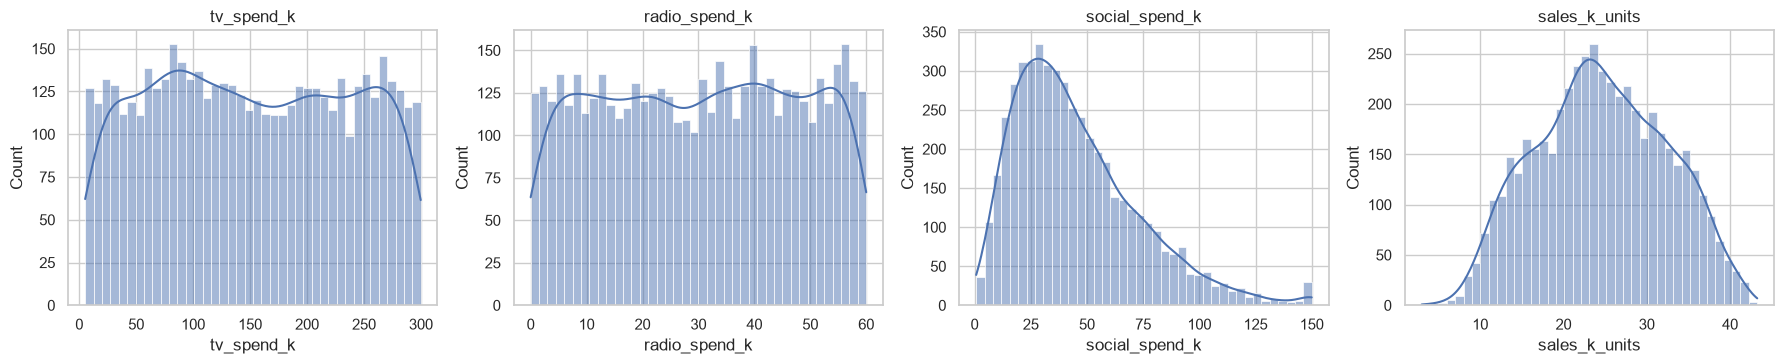

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, features + [target]):
    sns.histplot(data=df, x=col, bins=40, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

TV and radio budgets are spread fairly evenly. Social spend is **right-skewed**: most campaigns spend \$20k–\$60k but a few spend much more. Keep that in mind, because polynomials can behave badly in sparse regions of the data.

### 3.2 How does each feature relate to sales?

Below, the grey dots are campaigns, the **red dashed line** is the best straight line, and the **black line** connects the *average* sales within narrow bins of spend. If the black line bends away from the red one, a straight line is not enough.

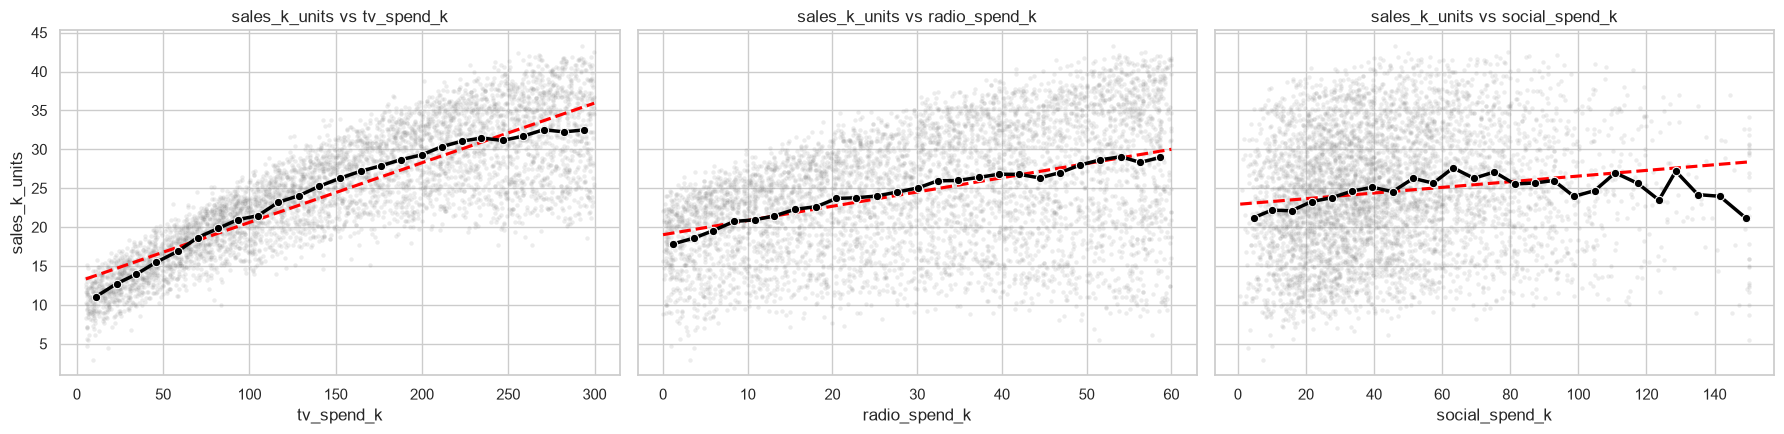

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, col in zip(axes, features):
    sns.scatterplot(data=df, x=col, y=target, alpha=0.15, s=10, color="grey", ax=ax)
    sns.regplot(data=df, x=col, y=target, scatter=False, ci=None,
                line_kws={"color": "red", "ls": "--"}, ax=ax)
    # binned means: a simple non-parametric "trend line"
    bins = pd.cut(df[col], 25)
    binned = df.groupby(bins, observed=True).agg(x=(col, "mean"), y=(target, "mean"))
    sns.lineplot(data=binned, x="x", y="y", color="black", lw=2.5, marker="o", ax=ax)
    ax.set_title(f"{target} vs {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**What do we see?**

- **TV:** sales rise quickly at first, then flatten out. Classic *diminishing returns*.
- **Radio:** looks closer to a straight line here, with gentle flattening at the top. Part of radio's story is hidden: as we'll discover, its effect depends on how much is spent on TV, and one-variable plots like these can't show interactions.
- **Social:** sales rise, level off around 60k–90k, and even fall at very high spend (think *ad fatigue*: people get annoyed by seeing the same ad over and over).

TV and social clearly bend. These are exactly the patterns a polynomial term can capture.

### 3.3 Correlations

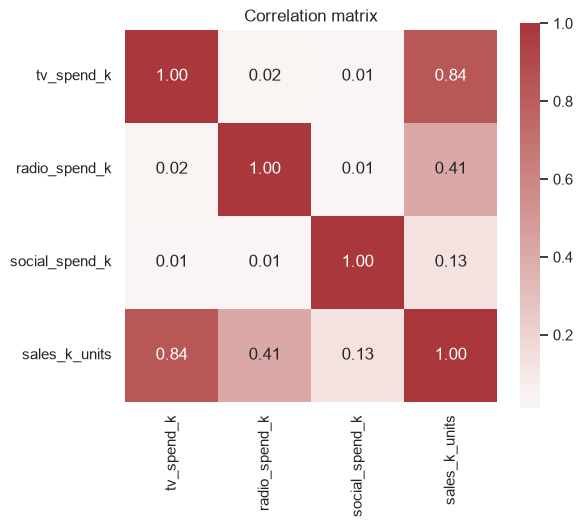

In [8]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation matrix")
plt.show()

The features are essentially uncorrelated with each other (budgets were set independently), and all three are positively correlated with sales. Note that correlation only measures **linear** association, so it doesn't tell us anything about curvature or interactions.

## 4. Train/test split

We split the data **once**, at the start:

- **Training set (80%)**: used for everything: fitting, comparing models, choosing the degree.
- **Test set (20%)**: locked away until the very end, then used **exactly once** to estimate how the final model performs on new data.

If we used the test set to *choose* the degree, it would no longer be an honest estimate of future performance. We would have tuned the model to it.

In [9]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train)}   Test rows: {len(X_test)}")

Training rows: 4000   Test rows: 1000


## 5. Baseline: ordinary linear regression

Before adding complexity, fit the simplest reasonable model. Any polynomial model must beat this baseline to be worth its extra complexity.

### Our two evaluation metrics

**R² (coefficient of determination):** the fraction of the variance in $y$ that the model explains.

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$

- $R^2 = 1$: perfect predictions. $R^2 = 0$: no better than always predicting the mean. It can be negative for very bad models.
- Unitless, so it's handy for comparing across problems.

**RMSE (root mean squared error):** the typical size of a prediction error, in the **same units as $y$**.

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_i (y_i - \hat{y}_i)^2}$$

- Lower is better. Here, an RMSE of 2 means predictions are typically off by about 2,000 units.
- Easy to communicate to non-statisticians ("we're usually within about X units").

The two metrics complement each other: R² tells you *how much* of the pattern you captured, and RMSE tells you *how wrong* you are in real terms.

In [10]:
def evaluate(model, X, y):
    # Return R² and RMSE for a fitted model on the given data
    pred = model.predict(X)
    return {"R2": r2_score(y, pred), "RMSE": root_mean_squared_error(y, pred)}

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Linear regression on the TRAINING data:")
print(evaluate(linear_model, X_train, y_train))
print("\nIntercept:", round(linear_model.intercept_, 3))
pd.Series(linear_model.coef_, index=features, name="coefficient")

Linear regression on the TRAINING data:
{'R2': 0.8709445166534173, 'RMSE': 2.786091516624905}

Intercept: 6.41


tv_spend_k        0.0757
radio_spend_k     0.1707
social_spend_k    0.0332
Name: coefficient, dtype: float64

An R² around 0.87 looks respectable. **But a good R² does not mean the model is *correctly specified*.** The best way to check is a **residual plot**: residuals ($y - \hat{y}$) plotted against predictions. For a well-specified model the residuals should look like a structureless cloud centred on zero.

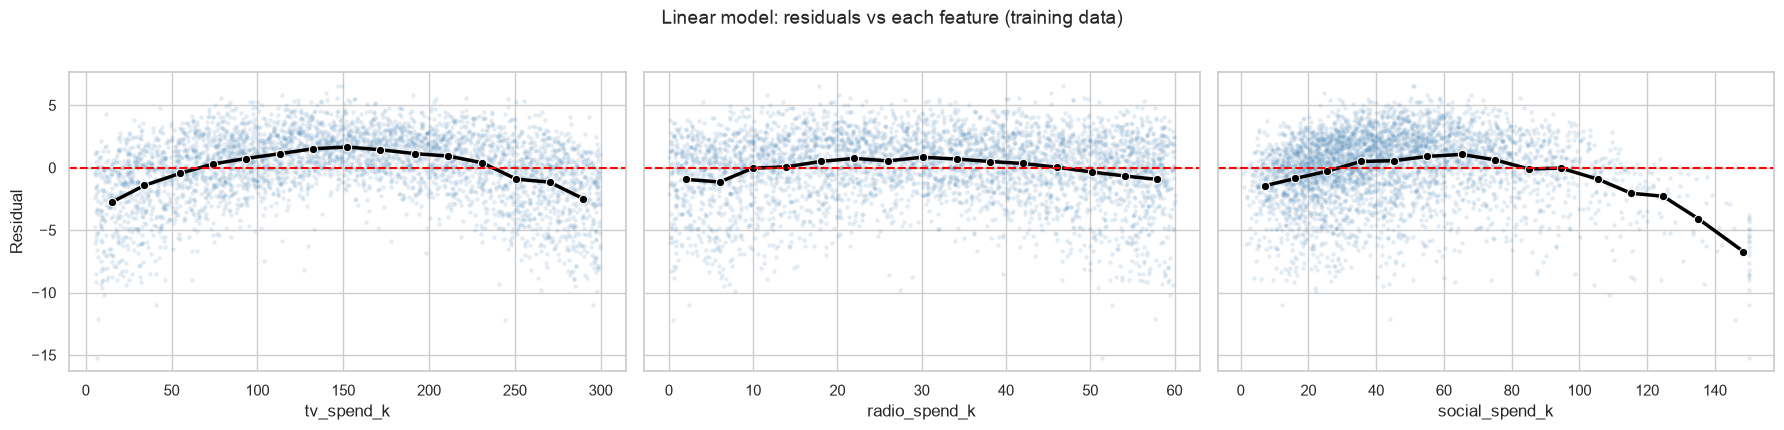

In [11]:
def plot_residuals_by_feature(X, resid, title):
    # Scatter residuals against each feature, with a black line of binned means.
    # If the model is well specified, the black line should stay flat at zero.
    fig, axes = plt.subplots(1, len(features), figsize=(18, 4.2), sharey=True)
    for ax, col in zip(axes, features):
        sns.scatterplot(x=X[col], y=resid, alpha=0.15, s=10, color="steelblue", ax=ax)
        binned = (pd.DataFrame({"x": X[col], "r": resid})
                  .groupby(pd.cut(X[col], 15), observed=True).mean())
        sns.lineplot(data=binned, x="x", y="r", color="black", lw=2.5, marker="o", ax=ax)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=col, ylabel="Residual")
    fig.suptitle(title, y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

resid_lin = y_train - linear_model.predict(X_train)
plot_residuals_by_feature(X_train, resid_lin, "Linear model: residuals vs each feature (training data)")

Against every feature there is a clear **upside-down U** in the residuals (the black line). The model systematically **under-predicts** for middling budgets (positive residuals) and **over-predicts** at low and high budgets (negative residuals). This is the fingerprint of **underfitting**: a straight line is too simple for the data.

> **Lessons:**
> - Never judge a regression by R² alone. Always look at the residuals.
> - With several features, plot residuals against **each feature**. The popular "residuals vs predicted" plot can hide this kind of pattern, because curvature in different features gets mixed together.

## 6. Feature transformation with `PolynomialFeatures`

`PolynomialFeatures(degree=d)` takes your original columns and generates **all powers and products up to total degree $d$**. Let's see exactly what it produces on a tiny toy table.

In [12]:
toy = pd.DataFrame({"a": [1, 2, 3], "b": [4, 5, 6]})

poly_toy = PolynomialFeatures(degree=2, include_bias=False)
toy_transformed = poly_toy.fit_transform(toy)

pd.DataFrame(toy_transformed, columns=poly_toy.get_feature_names_out())

,a,b,a^2,a b,b^2
0,1.0,4.0,1.0,4.0,16.0
1,2.0,5.0,4.0,10.0,25.0
2,3.0,6.0,9.0,18.0,36.0


Check row 1 by hand: $a=1, b=4$ gives $a^2 = 1$, $ab = 4$, $b^2 = 16$. ✔

Notes:

- `include_bias=False` drops the column of 1s. `LinearRegression` already fits an intercept, so we don't need it.
- `get_feature_names_out()` tells you what each new column means. Very useful for interpreting coefficients later.

Now apply it to our three advertising features:

In [13]:
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly2 = poly2.fit_transform(X_train)

print("Original shape:   ", X_train.shape)
print("Transformed shape:", X_train_poly2.shape)
print("\nNew feature names:")
for name in poly2.get_feature_names_out():
    print("  ", name)

Original shape:    (4000, 3)
Transformed shape: (4000, 9)

New feature names:
   tv_spend_k
   radio_spend_k
   social_spend_k
   tv_spend_k^2
   tv_spend_k radio_spend_k
   tv_spend_k social_spend_k
   radio_spend_k^2
   radio_spend_k social_spend_k
   social_spend_k^2


From 3 features we now have 9: the 3 originals, 3 squares, and 3 **pairwise interactions**. The interaction `tv_spend_k radio_spend_k` lets the effect of radio depend on how much is spent on TV.

### 6.1 The number of features explodes with the degree

With $p$ original features and degree $d$, `PolynomialFeatures` creates $\binom{p+d}{d} - 1$ columns (excluding the bias). More columns means more coefficients to estimate, which means more flexibility and more risk of overfitting.

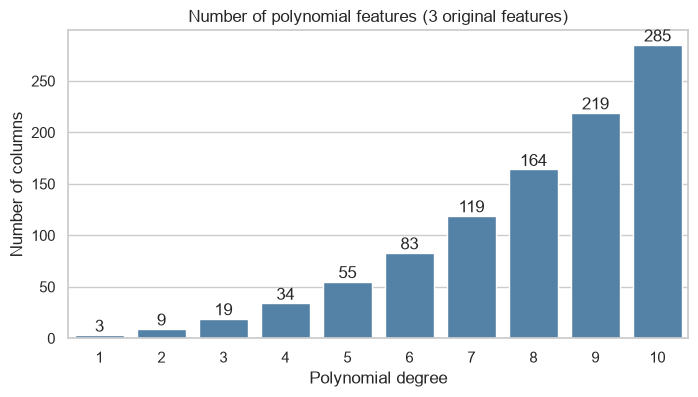

,degree,n_features,formula
0,1,3,3
1,2,9,9
2,3,19,19
3,4,34,34
4,5,55,55
5,6,83,83
6,7,119,119
7,8,164,164
8,9,219,219
9,10,285,285


In [14]:
rows = []
for d in range(1, 11):
    n_cols = PolynomialFeatures(degree=d, include_bias=False).fit(X_train).n_output_features_
    rows.append({"degree": d, "n_features": n_cols, "formula": comb(3 + d, d) - 1})
feature_counts = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=feature_counts, x="degree", y="n_features", color="steelblue")
ax.bar_label(ax.containers[0])
ax.set(title="Number of polynomial features (3 original features)",
       xlabel="Polynomial degree", ylabel="Number of columns")
plt.show()
feature_counts

At degree 10 we would be estimating 285 coefficients from 3 original measurements!

### 6.2 Why we scale the features first

Raising large numbers to high powers produces **enormous** values. TV spend goes up to 300, so $\text{tv}^4 \approx 8 \times 10^{9}$, while radio is at most 60. Columns with wildly different magnitudes make the numerical computations behind linear regression unstable.

In [15]:
poly4 = PolynomialFeatures(degree=4, include_bias=False)
X_train_poly4 = pd.DataFrame(poly4.fit_transform(X_train), columns=poly4.get_feature_names_out())

col_max = X_train_poly4.abs().max()
print(f"Smallest column max: {col_max.min():,.0f}")
print(f"Largest column max:  {col_max.max():,.0f}")
print(f"Ratio:               {col_max.max() / col_max.min():,.0f}x")

Smallest column max: 60
Largest column max:  8,078,421,590
Ratio:               134,640,360x


The fix is to **standardise** the original features with `StandardScaler` (subtract the mean, divide by the standard deviation) **before** creating polynomial terms. All values then sit roughly between −3 and 3, so their powers stay manageable.

For plain `LinearRegression`, scaling doesn't change the predictions mathematically. It just keeps the computation numerically healthy. (If you later use *regularised* models like Ridge or Lasso, scaling becomes essential.)

## 7. Building a pipeline and training a degree-2 model

A scikit-learn `Pipeline` chains the steps together so they behave like a single model:

`StandardScaler` → `PolynomialFeatures` → `LinearRegression`

Why bother with a pipeline?

- **Convenience:** one `.fit()` and one `.predict()` call run every step in the right order.
- **No data leakage:** during cross-validation (Section 11), the scaler is re-fitted on each training fold only, so information from the validation fold never leaks into training.
- **Easy experimentation:** changing the degree is one argument.

In [16]:
def make_poly_model(degree):
    # Build a polynomial regression pipeline of the given degree
    return Pipeline([
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("linreg", LinearRegression()),
    ])

quad_model = make_poly_model(degree=2)
quad_model.fit(X_train, y_train)
quad_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['tv_spend_k','radio_spend_k','social_spend_k']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [17]:
comparison = pd.DataFrame({
    "Linear (degree 1)": evaluate(linear_model, X_train, y_train),
    "Polynomial (degree 2)": evaluate(quad_model, X_train, y_train),
}).T
comparison

,R2,RMSE
Linear (degree 1),0.8709,2.7861
Polynomial (degree 2),0.9718,1.3030


Moving from degree 1 to degree 2 raises R² from about 0.87 to about 0.97 and cuts the RMSE substantially. Let's check whether the curved pattern in the residuals has gone.

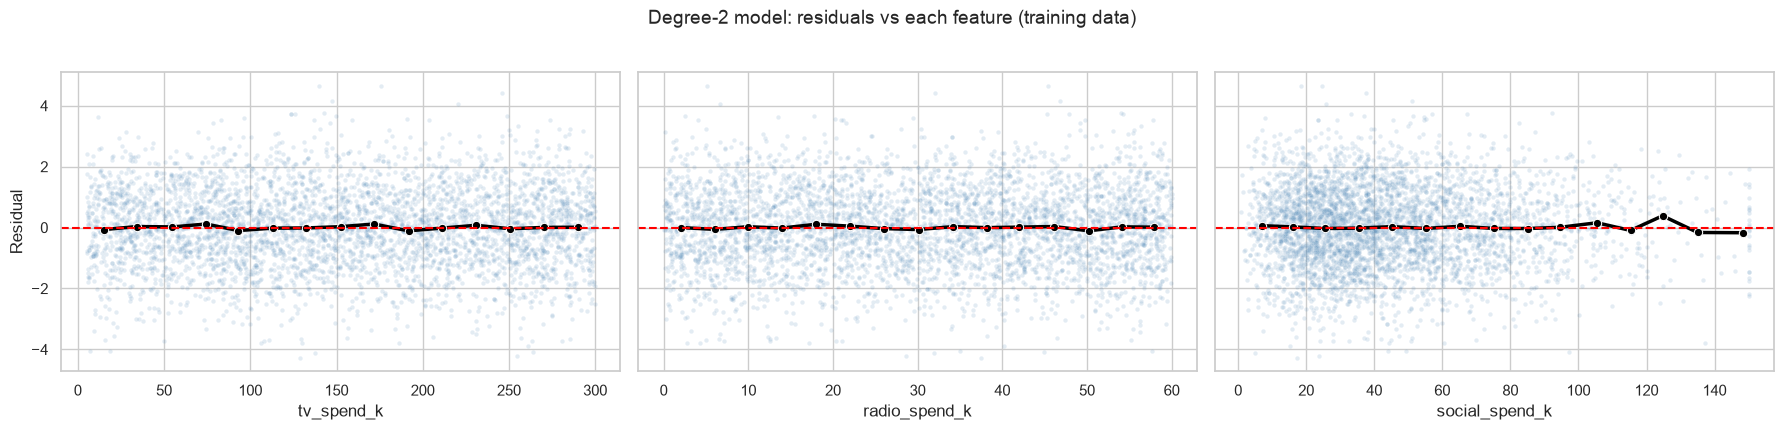

In [18]:
resid_quad = y_train - quad_model.predict(X_train)
plot_residuals_by_feature(X_train, resid_quad, "Degree-2 model: residuals vs each feature (training data)")

The black lines are now **flat at zero**. The upside-down U is gone, and what's left looks like random noise. That's what a well-specified model looks like.

But these are **training** scores. A more flexible model will *always* score at least as well on the data it was trained on. The real question is how it does on data it hasn't seen. Before answering that for our full model, let's build intuition with a simple picture.

## 8. Seeing underfitting and overfitting in one dimension

To visualise what the degree does, we'll use **just one feature** (TV spend) and a **small sample of 30 campaigns**. Small samples make overfitting easy to see.

For each degree we report the RMSE on the 30 training points and on all the **other** campaigns, which the model never saw.

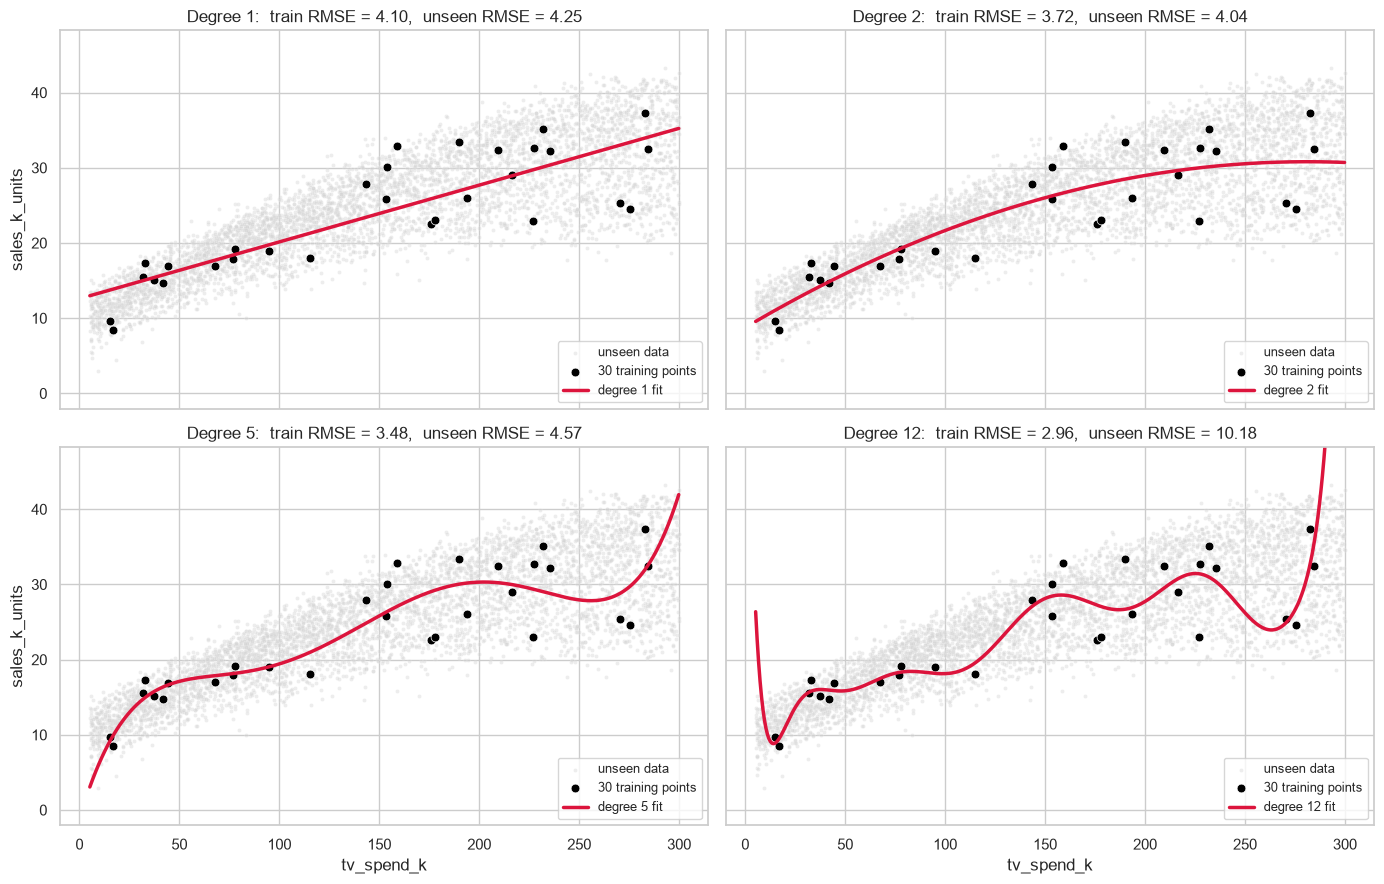

In [19]:
small = df.sample(30, random_state=8)
rest = df.drop(small.index)

x_grid = pd.DataFrame({"tv_spend_k": np.linspace(df["tv_spend_k"].min(),
                                                 df["tv_spend_k"].max(), 400)})
degrees_1d = [1, 2, 5, 12]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, d in zip(axes.ravel(), degrees_1d):
    m = make_poly_model(d).fit(small[["tv_spend_k"]], small[target])
    rmse_tr = root_mean_squared_error(small[target], m.predict(small[["tv_spend_k"]]))
    rmse_new = root_mean_squared_error(rest[target], m.predict(rest[["tv_spend_k"]]))

    sns.scatterplot(data=rest, x="tv_spend_k", y=target, color="lightgrey", s=8, alpha=0.4, ax=ax,
                    label="unseen data")
    sns.scatterplot(data=small, x="tv_spend_k", y=target, color="black", s=40, ax=ax,
                    label="30 training points")
    sns.lineplot(x=x_grid["tv_spend_k"], y=m.predict(x_grid), color="crimson", lw=2.5, ax=ax,
                 label=f"degree {d} fit")
    ax.set_title(f"Degree {d}:  train RMSE = {rmse_tr:.2f},  unseen RMSE = {rmse_new:.2f}")
    ax.set_ylim(df[target].min() - 5, df[target].max() + 5)
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

Reading the four panels:

- **Degree 1, underfit.** The line misses the bend. Training and unseen errors are both relatively high. This is **high bias**: the model is too rigid.
- **Degree 2, about right.** It captures the rise-and-level-off shape, and it has the lowest error on unseen data.
- **Degree 5.** Training error is lower, but unseen error is already worse. The curve is starting to bend in places the data doesn't justify, especially near the edges.
- **Degree 12, overfit.** The curve chases individual points and swings wildly between and beyond them. Training error is the lowest of all, but error on unseen data is far worse. This is **high variance**: the model memorised the noise in these particular 30 points.

> **The core lesson:** training error always goes down as the degree goes up. Error on new data goes down, then **back up**. We want the degree at the bottom of that second curve.

(Note: the scatter is wide because this plot ignores radio and social spend, which also drive sales. That's fine for building intuition.)

## 9. Iterative evaluation of polynomial degrees

Now back to the full three-feature problem. To compare degrees on unseen data **without touching the test set**, we carve a **validation set** out of the training data:

- **sub-training set (75% of training)**: fit each model
- **validation set (25% of training)**: score each model

Then we loop over degrees 1 to 8, record R² and RMSE on both sets, and plot the results.

In [20]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=RANDOM_STATE
)
print(f"Sub-training rows: {len(X_subtrain)}   Validation rows: {len(X_val)}")

Sub-training rows: 3000   Validation rows: 1000


In [21]:
degrees = range(1, 9)
results = []

for d in degrees:
    model = make_poly_model(d)
    model.fit(X_subtrain, y_subtrain)

    train_scores = evaluate(model, X_subtrain, y_subtrain)
    val_scores = evaluate(model, X_val, y_val)

    results.append({
        "degree": d,
        "n_features": model.named_steps["poly"].n_output_features_,
        "train_R2": train_scores["R2"],
        "val_R2": val_scores["R2"],
        "train_RMSE": train_scores["RMSE"],
        "val_RMSE": val_scores["RMSE"],
    })

results_df = pd.DataFrame(results)
results_df

,degree,n_features,train_R2,val_R2,train_RMSE,val_RMSE
0,1,3,0.8739,0.8613,2.7650,2.8501
1,2,9,0.9716,0.9721,1.3126,1.2771
2,3,19,0.9717,0.9722,1.3108,1.2760
3,4,34,0.9719,0.9719,1.3063,1.2836
4,5,55,0.9721,0.9716,1.3016,1.2900
5,6,83,0.9723,0.9713,1.2964,1.2965
6,7,119,0.9727,0.9701,1.2871,1.3240
7,8,164,0.9732,0.9490,1.2758,1.7286


Seaborn works best with data in **long format** (one row per observation, one column per variable), so we reshape before plotting.

In [22]:
results_long = results_df.melt(
    id_vars=["degree"],
    value_vars=["train_R2", "val_R2", "train_RMSE", "val_RMSE"],
    var_name="metric_split", value_name="score",
)
results_long[["split", "metric"]] = results_long["metric_split"].str.split("_", expand=True)
results_long["split"] = results_long["split"].map({"train": "training", "val": "validation"})
results_long.head()

,degree,metric_split,score,split,metric
0,1,train_R2,0.8739,training,R2
1,2,train_R2,0.9716,training,R2
2,3,train_R2,0.9717,training,R2
3,4,train_R2,0.9719,training,R2
4,5,train_R2,0.9721,training,R2


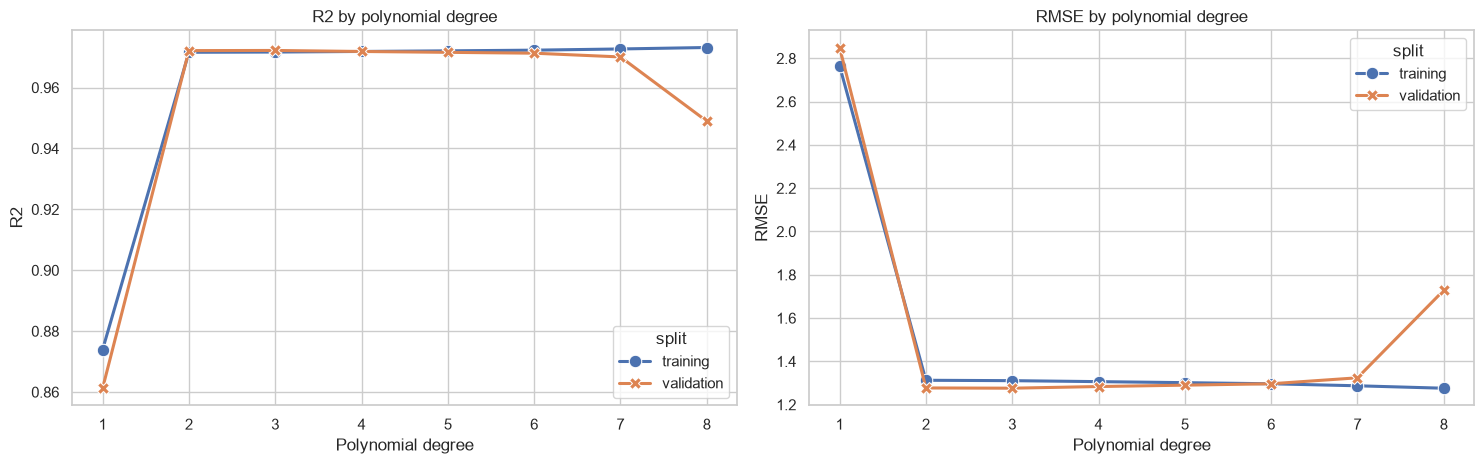

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, metric in zip(axes, ["R2", "RMSE"]):
    sns.lineplot(data=results_long[results_long["metric"] == metric],
                 x="degree", y="score", hue="split", style="split",
                 markers=True, dashes=False, markersize=9, lw=2.2, ax=ax)
    ax.set(title=f"{metric} by polynomial degree", xlabel="Polynomial degree", ylabel=metric)
    ax.set_xticks(list(degrees))
plt.tight_layout()
plt.show()

The big story is the jump from degree 1 to degree 2. After that, both curves look flat. Let's zoom in on degrees 2 and above, where the differences are small.

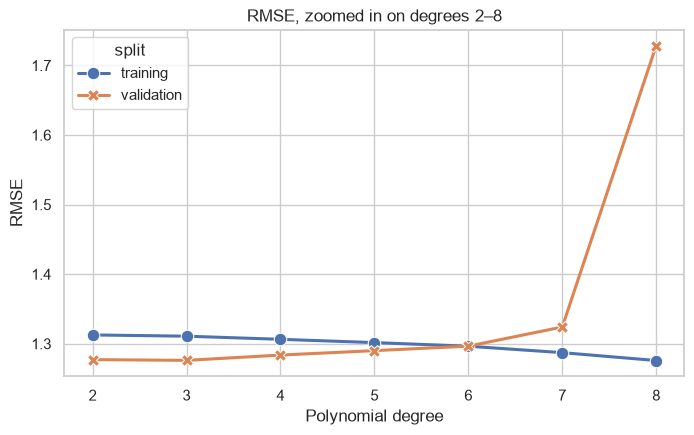

In [24]:
zoom = results_long[(results_long["metric"] == "RMSE") & (results_long["degree"] >= 2)]

plt.figure(figsize=(8, 4.5))
ax = sns.lineplot(data=zoom, x="degree", y="score", hue="split", style="split",
                  markers=True, dashes=False, markersize=9, lw=2.2)
ax.set(title="RMSE, zoomed in on degrees 2–8", xlabel="Polynomial degree", ylabel="RMSE")
ax.set_xticks(range(2, 9))
plt.show()

Zoomed in, the classic pattern appears:

- **Training RMSE keeps falling** as the degree increases. More flexibility always fits the training data better.
- (Don't be surprised that validation RMSE is slightly *below* training RMSE at low degrees. With random noise, a particular validation set can be a little "easier" by chance.)
- **Validation RMSE is flat at degrees 2–3**, then creeps upward from degree 4 and jumps at degree 8 as the extra terms start fitting noise.

Notice that degree 3 has a *very slightly* lower validation RMSE than degree 2 on this particular split. The difference is in the third decimal place. Is that a real improvement or just luck in which rows ended up in the validation set? A single split can't tell us. We'll answer that properly in Section 11.

The overfitting here is **mild**, because we have about 3,000 sub-training rows and even degree 8 has only 164 features, so there are plenty of rows per coefficient. The next section shows what happens when that ratio is less favourable.

## 10. When overfitting is really dangerous: a small dataset

Overfitting depends on the **number of rows relative to the number of model coefficients**. Let's repeat the experiment using only **150 training rows**, about what you might have from a few years of monthly campaigns.

Remember from Section 6.1: degree 6 has 83 features and degree 8 has 164, which is more coefficients than data points!

In [25]:
X_small, _, y_small, _ = train_test_split(X_subtrain, y_subtrain, train_size=150,
                                          random_state=RANDOM_STATE)

small_results = []
for d in degrees:
    model = make_poly_model(d).fit(X_small, y_small)
    small_results.append({
        "degree": d,
        "n_features": model.named_steps["poly"].n_output_features_,
        "training": root_mean_squared_error(y_small, model.predict(X_small)),
        "validation": root_mean_squared_error(y_val, model.predict(X_val)),
    })
small_df = pd.DataFrame(small_results)
small_df

,degree,n_features,training,validation
0,1,3,2.5841,2.8589
1,2,9,1.2180,1.3616
2,3,19,1.1762,1.4268
3,4,34,1.1007,1.5069
4,5,55,0.9883,1.8736
5,6,83,0.8868,17.9927
6,7,119,0.6701,177.6832
7,8,164,0.3042,982.9719


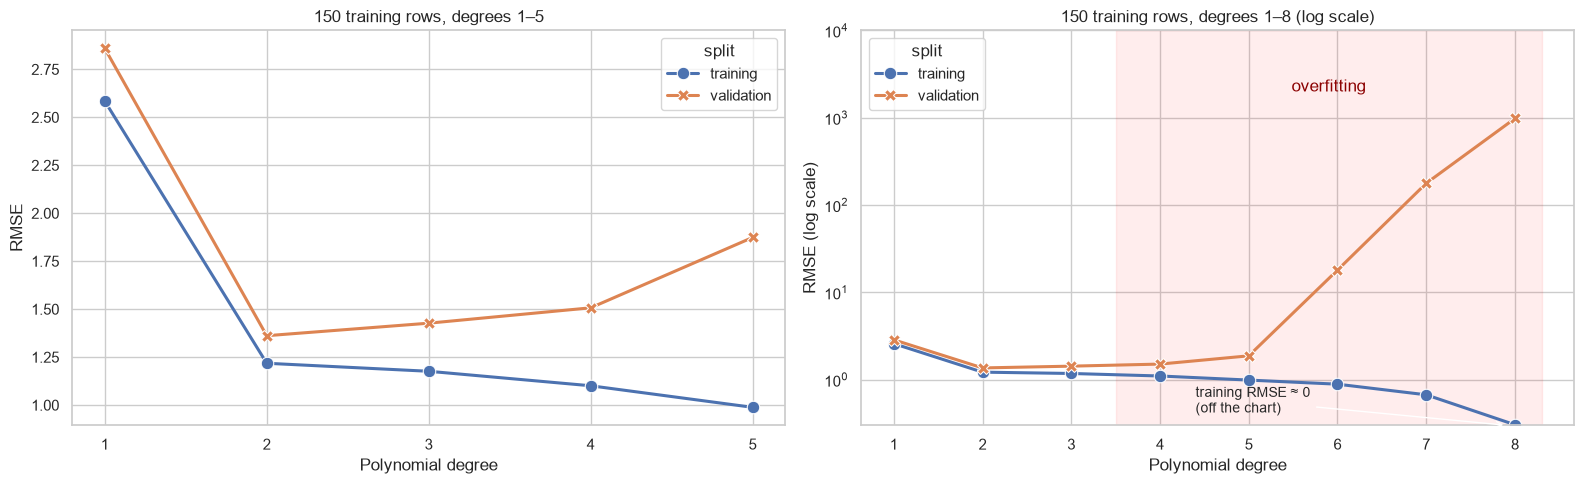

In [26]:
small_long = small_df.melt(id_vars=["degree", "n_features"], var_name="split", value_name="RMSE")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: ordinary scale, degrees 1-5, to see the start of the U shape
sns.lineplot(data=small_long[small_long["degree"] <= 5], x="degree", y="RMSE", hue="split",
             style="split", markers=True, dashes=False, markersize=9, lw=2.2, ax=axes[0])
axes[0].set(title="150 training rows, degrees 1–5", xlabel="Polynomial degree", ylabel="RMSE")
axes[0].set_xticks(range(1, 6))

# Right: log scale, all degrees, because validation error explodes
sns.lineplot(data=small_long, x="degree", y="RMSE", hue="split", style="split",
             markers=True, dashes=False, markersize=9, lw=2.2, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_ylim(0.3, 1e4)
axes[1].set(title="150 training rows, degrees 1–8 (log scale)",
            xlabel="Polynomial degree", ylabel="RMSE (log scale)")
axes[1].set_xticks(list(degrees))
axes[1].axvspan(3.5, 8.3, color="red", alpha=0.07)
axes[1].text(5.9, 2000, "overfitting", color="darkred", fontsize=12, ha="center")
axes[1].annotate("training RMSE ≈ 0\n(off the chart)", xy=(7.9, 0.3), xytext=(4.4, 0.42),
                 arrowprops={"arrowstyle": "->"}, fontsize=10)
plt.tight_layout()
plt.show()

This is the textbook **bias–variance trade-off**:

- At degree 1 (**high bias**), both errors are high because the model is too simple.
- At degree 2, validation error is at its minimum. This is the sweet spot.
- From degree 3 onward, training error keeps falling but validation error **rises**: 1.36 → 1.43 → 1.51 → 1.87 (left panel).
- At high degrees (**high variance**, right panel), training error drops toward zero while validation error **explodes**. By degree 8 the model has more coefficients than training rows, so it can essentially pass through every training point, and its predictions on new data are useless.

> **Takeaway:** the "right" degree depends on how much data you have. With less data, you should prefer simpler models.

## 11. Choosing the degree robustly with cross-validation

A single validation split has a weakness: the result depends on **which** rows happened to land in the validation set. A different random split might favour a different degree.

**k-fold cross-validation** fixes this. The training data is split into $k$ folds (we'll use $k = 5$). Each fold takes a turn as the validation set while the model is trained on the other four. We then average the $k$ scores and also look at their **spread**.

```
Fold 1:  [VAL ] [train] [train] [train] [train]
Fold 2:  [train] [VAL ] [train] [train] [train]
Fold 3:  [train] [train] [VAL ] [train] [train]
Fold 4:  [train] [train] [train] [VAL ] [train]
Fold 5:  [train] [train] [train] [train] [VAL ]
```

`cross_validate` does all of this for us. Because our model is a `Pipeline`, the scaler is re-fitted inside every fold, so there's no leakage.

*Note:* scikit-learn's scorers follow a "bigger is better" convention, so RMSE is returned as a **negative** number (`neg_root_mean_squared_error`). We flip the sign back.

In [27]:
N_FOLDS = 5
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for d in degrees:
    scores = cross_validate(
        make_poly_model(d), X_train, y_train, cv=cv,
        scoring={"R2": "r2", "RMSE": "neg_root_mean_squared_error"},
        return_train_score=True,
    )
    for fold in range(N_FOLDS):
        cv_rows.append({
            "degree": d, "fold": fold + 1,
            "train_R2": scores["train_R2"][fold],
            "val_R2": scores["test_R2"][fold],
            "train_RMSE": -scores["train_RMSE"][fold],
            "val_RMSE": -scores["test_RMSE"][fold],
        })

cv_df = pd.DataFrame(cv_rows)
cv_df.head(10)

,degree,fold,train_R2,val_R2,train_RMSE,val_RMSE
0,1,1,0.8728,0.8622,2.7772,2.8247
1,1,2,0.8700,0.8746,2.7889,2.7757
2,1,3,0.8716,0.8678,2.7968,2.7454
3,1,4,0.8722,0.8661,2.7629,2.8779
4,1,5,0.8682,0.8811,2.8027,2.7201
5,2,1,0.9715,0.9727,1.3145,1.2583
6,2,2,0.9713,0.9736,1.3112,1.2731
7,2,3,0.9726,0.9680,1.2913,1.3504
8,2,4,0.9719,0.9714,1.2965,1.3297
9,2,5,0.9717,0.9720,1.2995,1.3195


Summarise each degree with the mean and standard deviation across the 5 folds:

In [28]:
cv_summary = cv_df.groupby("degree").agg(
    mean_val_R2=("val_R2", "mean"),
    mean_val_RMSE=("val_RMSE", "mean"),
    std_val_RMSE=("val_RMSE", "std"),
    mean_train_RMSE=("train_RMSE", "mean"),
)
cv_summary

,mean_val_R2,mean_val_RMSE,std_val_RMSE,mean_train_RMSE
degree,,,,
1,0.8704,2.7887,0.0632,2.7857
2,0.9715,1.3062,0.0390,1.3026
3,0.9715,1.3080,0.0421,1.3001
4,0.9713,1.3111,0.0415,1.2968
5,0.9711,1.3173,0.0425,1.2923
6,0.9706,1.3277,0.0409,1.2870
7,0.9702,1.3374,0.0301,1.2792
8,0.9685,1.3741,0.0520,1.2706


Seaborn can draw the mean **and** an uncertainty band directly from the per-fold rows. Here `errorbar="sd"` shades ±1 standard deviation across folds.

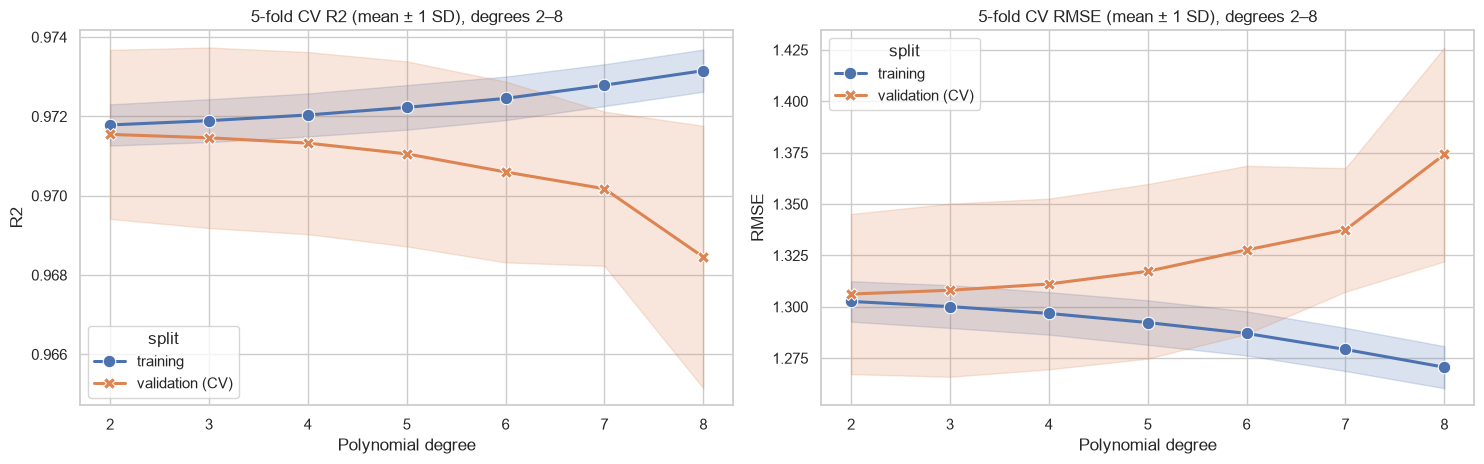

In [29]:
cv_long = cv_df.melt(id_vars=["degree", "fold"], var_name="metric_split", value_name="score")
cv_long[["split", "metric"]] = cv_long["metric_split"].str.split("_", expand=True)
cv_long["split"] = cv_long["split"].map({"train": "training", "val": "validation (CV)"})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, metric in zip(axes, ["R2", "RMSE"]):
    data = cv_long[(cv_long["metric"] == metric) & (cv_long["degree"] >= 2)]
    sns.lineplot(data=data, x="degree", y="score", hue="split", style="split",
                 errorbar="sd", markers=True, dashes=False, markersize=9, lw=2.2, ax=ax)
    ax.set(title=f"5-fold CV {metric} (mean ± 1 SD), degrees 2–8",
           xlabel="Polynomial degree", ylabel=metric)
    ax.set_xticks(range(2, 9))
plt.tight_layout()
plt.show()

### 11.1 Two rules for picking the degree

**Rule 1: minimum CV error.** Pick the degree with the lowest mean validation RMSE.

**Rule 2: the one-standard-error rule** (a common rule of thumb). Differences smaller than the noise in our estimate aren't meaningful. So:

1. Find the degree with the minimum mean CV RMSE.
2. Compute its **standard error**: $\text{SE} = \text{SD} / \sqrt{k}$.
3. Choose the **simplest** degree whose mean CV RMSE is within one SE of that minimum.

Rule 2 embodies **parsimony** (Occam's razor): if a simpler model is statistically just as good, prefer it. Simpler models are easier to interpret, faster, and less likely to behave strangely on new data, especially at the edges of the data range.

In [30]:
cv_summary["se_val_RMSE"] = cv_summary["std_val_RMSE"] / np.sqrt(N_FOLDS)

min_degree = cv_summary["mean_val_RMSE"].idxmin()
threshold = cv_summary.loc[min_degree, "mean_val_RMSE"] + cv_summary.loc[min_degree, "se_val_RMSE"]
one_se_degree = cv_summary.index[cv_summary["mean_val_RMSE"] <= threshold].min()

print(f"Degree with minimum mean CV RMSE: {min_degree}  "
      f"(RMSE = {cv_summary.loc[min_degree, 'mean_val_RMSE']:.4f})")
print(f"One-SE threshold:                 {threshold:.4f}")
print(f"Simplest degree within 1 SE:      {one_se_degree}")

Degree with minimum mean CV RMSE: 2  (RMSE = 1.3062)
One-SE threshold:                 1.3236
Simplest degree within 1 SE:      2


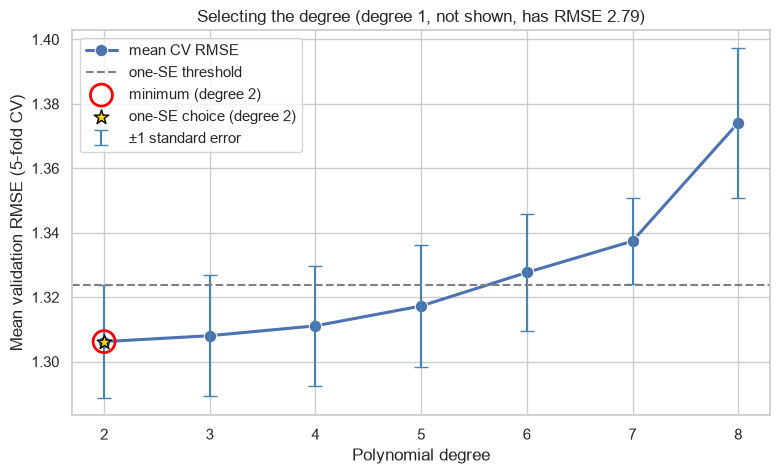

In [31]:
plot_df = cv_summary.reset_index()
plot_df = plot_df[plot_df["degree"] >= 2]  # degree 1 is far worse; leave it out so we can see the detail

plt.figure(figsize=(9, 5))
ax = sns.lineplot(data=plot_df, x="degree", y="mean_val_RMSE", marker="o", markersize=9, lw=2.2,
                  label="mean CV RMSE")
ax.errorbar(plot_df["degree"], plot_df["mean_val_RMSE"], yerr=plot_df["se_val_RMSE"],
            fmt="none", ecolor="steelblue", capsize=5, label="±1 standard error")
ax.axhline(threshold, color="grey", ls="--", label="one-SE threshold")
ax.scatter([min_degree], [cv_summary.loc[min_degree, "mean_val_RMSE"]], s=250,
           facecolors="none", edgecolors="red", lw=2, zorder=5, label=f"minimum (degree {min_degree})")
ax.scatter([one_se_degree], [cv_summary.loc[one_se_degree, "mean_val_RMSE"]], s=120, marker="*",
           color="gold", edgecolors="black", zorder=6, label=f"one-SE choice (degree {one_se_degree})")
ax.set(title=f"Selecting the degree (degree 1, not shown, has RMSE {cv_summary.loc[1, 'mean_val_RMSE']:.2f})",
       xlabel="Polynomial degree", ylabel="Mean validation RMSE (5-fold CV)")
ax.set_xticks(range(2, 9))
ax.legend()
plt.show()

Both rules point to **degree 2**.

Notice that degrees 3–5 also fall below the dashed threshold. Their CV error is statistically indistinguishable from degree 2's, yet they need 19 to 55 coefficients instead of 9. The one-SE rule says: when the evidence can't separate them, take the simplest. That also settles the question from Section 9, where degree 3 looked marginally better on one split. Cross-validation shows the difference was just noise.

### 11.2 A checklist for choosing the degree

When you choose a degree on your own projects, weigh all of these:

1. **Validation / CV error.** Look for where it stops improving, *not* where training error is lowest.
2. **Uncertainty.** If two degrees are within about one standard error of each other, prefer the simpler one.
3. **Train vs validation gap.** A growing gap is a warning sign of overfitting.
4. **Residual plots.** The chosen model should leave no obvious pattern behind.
5. **Domain sense.** Does the shape make sense? Diminishing returns are plausible. A curve that wiggles up and down between data points is not.
6. **Amount of data.** Fewer rows means you should favour lower degrees (Section 10).

## 12. Final evaluation on the test set

We've made every decision using only the training data. Now we:

1. Re-fit the chosen model on the **entire training set**.
2. Evaluate it **once** on the untouched test set.

We'll also evaluate the linear baseline on the test set for comparison.

In [32]:
best_degree = one_se_degree
final_model = make_poly_model(best_degree).fit(X_train, y_train)
baseline = LinearRegression().fit(X_train, y_train)

test_results = pd.DataFrame({
    "Linear baseline (degree 1)": evaluate(baseline, X_test, y_test),
    f"Polynomial (degree {best_degree})": evaluate(final_model, X_test, y_test),
}).T
test_results

,R2,RMSE
Linear baseline (degree 1),0.8778,2.7424
Polynomial (degree 2),0.9744,1.2564


In [33]:
improvement = 1 - test_results.iloc[1]["RMSE"] / test_results.iloc[0]["RMSE"]
print(f"The degree-{best_degree} model reduces test RMSE by {improvement:.0%} compared with the linear baseline.")
print(f"Typical prediction error: about {test_results.iloc[1]['RMSE'] * 1000:,.0f} units.")

The degree-2 model reduces test RMSE by 54% compared with the linear baseline.
Typical prediction error: about 1,256 units.


The test scores are very close to the cross-validation scores, which confirms that our CV estimate was honest and the model generalises well.

### 12.1 Predicted vs actual

Points on the dashed diagonal are perfect predictions.

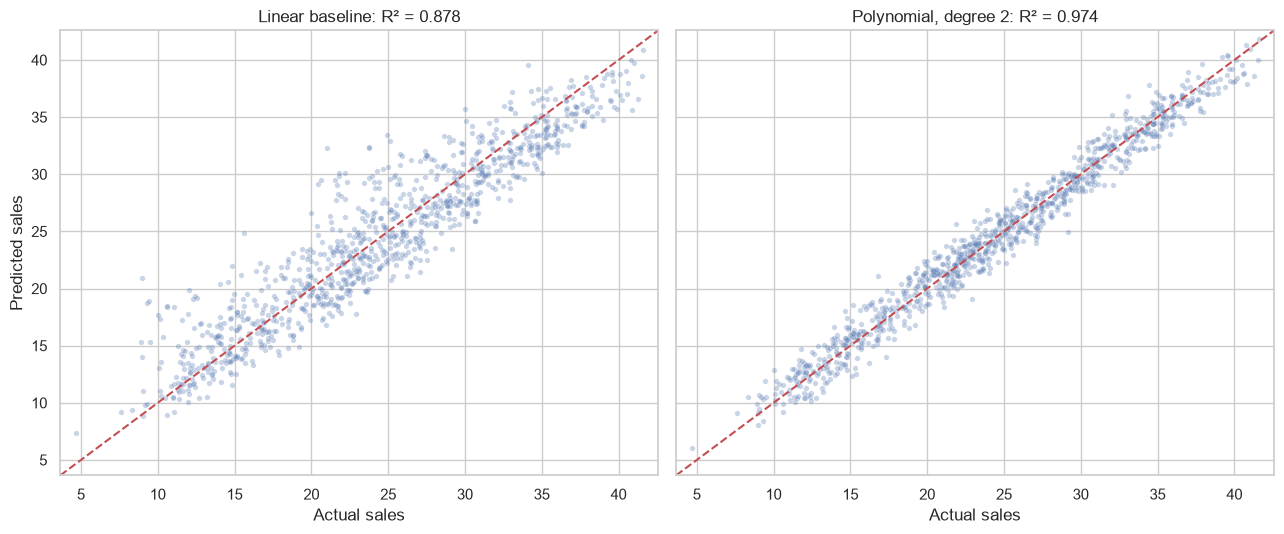

In [34]:
test_pred_lin = baseline.predict(X_test)
test_pred_poly = final_model.predict(X_test)
lims = [y_test.min() - 1, y_test.max() + 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, pred, title in [(axes[0], test_pred_lin, "Linear baseline"),
                        (axes[1], test_pred_poly, f"Polynomial, degree {best_degree}")]:
    sns.scatterplot(x=y_test, y=pred, alpha=0.3, s=15, ax=ax)
    ax.plot(lims, lims, "r--", lw=1.5)
    ax.set(xlim=lims, ylim=lims, title=f"{title}: R² = {r2_score(y_test, pred):.3f}",
           xlabel="Actual sales", ylabel="Predicted sales")
plt.tight_layout()
plt.show()

The linear model's points curve away from the diagonal at both ends, while the polynomial model's points hug it evenly across the whole range.

### 12.2 Residual diagnostics for the final model

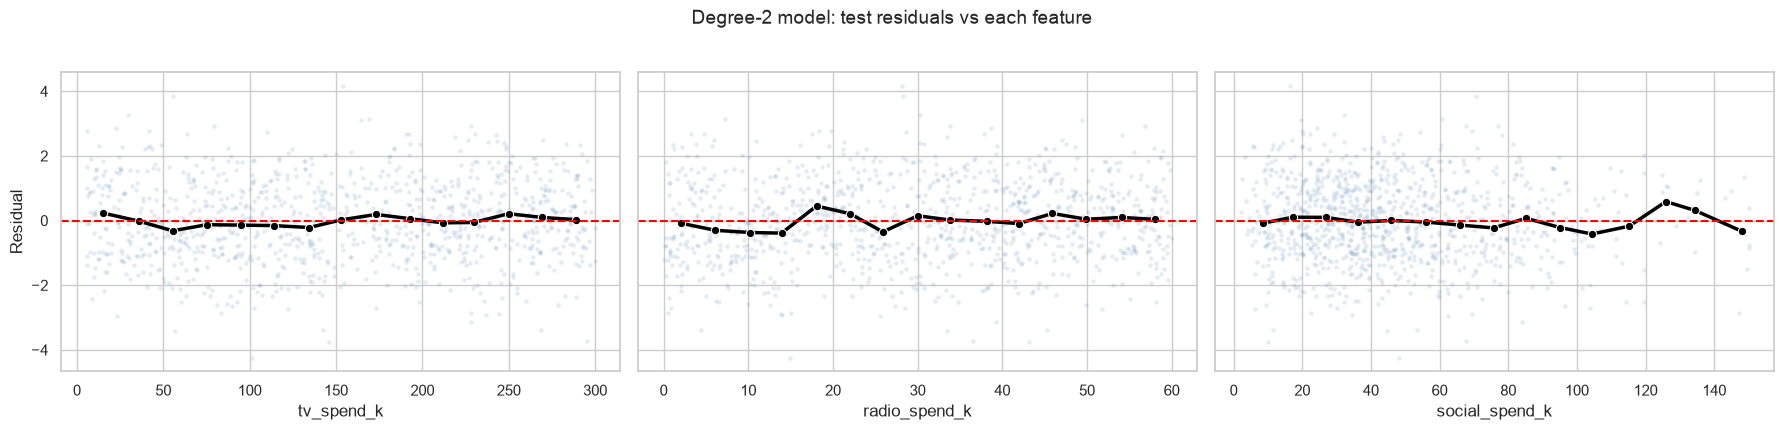

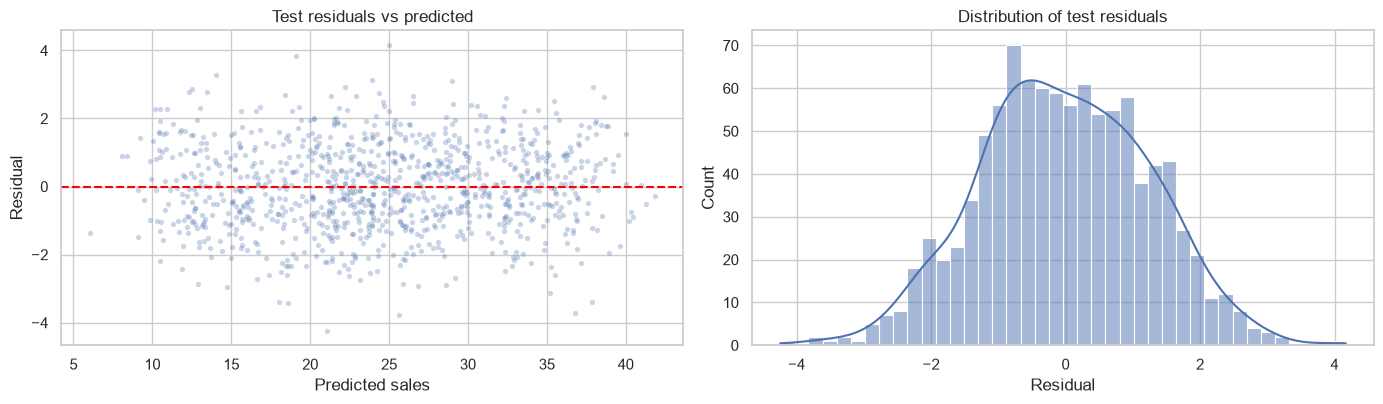

In [35]:
test_resid = y_test - test_pred_poly
plot_residuals_by_feature(X_test, test_resid, f"Degree-{best_degree} model: test residuals vs each feature")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.scatterplot(x=test_pred_poly, y=test_resid, alpha=0.3, s=15, ax=axes[0])
axes[0].axhline(0, color="red", ls="--")
axes[0].set(title="Test residuals vs predicted", xlabel="Predicted sales", ylabel="Residual")
sns.histplot(test_resid, bins=40, kde=True, ax=axes[1])
axes[1].set(title="Distribution of test residuals", xlabel="Residual")
plt.tight_layout()
plt.show()

The residuals show no pattern, are centred on zero, and are roughly bell-shaped. The remaining error is noise the model can't (and shouldn't try to) explain.

## 13. Interpreting the polynomial model

### 13.1 Coefficients

Because the features were standardised, the coefficients are on comparable scales. Each one is the effect of a one-standard-deviation change. Let's pull them out of the pipeline with their feature names.

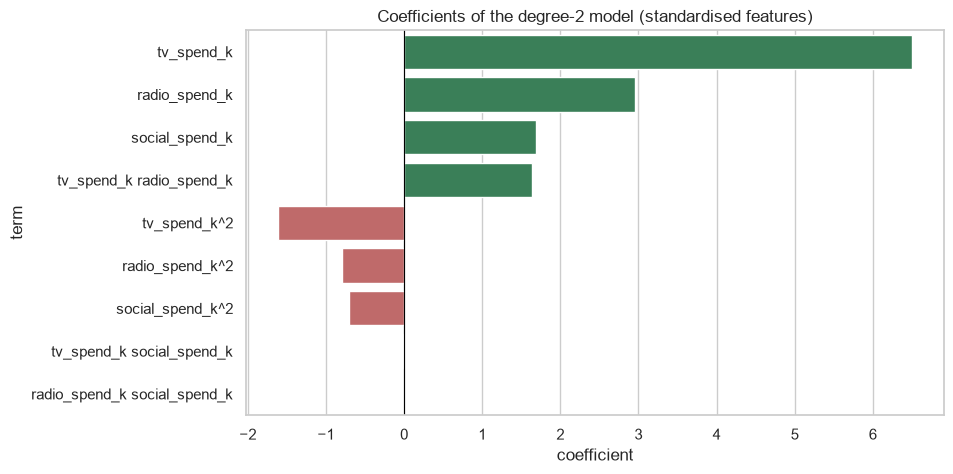

,term,coefficient
0,tv_spend_k,6.5032
1,radio_spend_k,2.9540
2,social_spend_k,1.6839
4,tv_spend_k radio_spend_k,1.6337
3,tv_spend_k^2,-1.6129
6,radio_spend_k^2,-0.7939
8,social_spend_k^2,-0.7088
5,tv_spend_k social_spend_k,-0.0157
7,radio_spend_k social_spend_k,-0.0074


In [36]:
names = final_model.named_steps["poly"].get_feature_names_out(features)
coefs = pd.DataFrame({
    "term": names,
    "coefficient": final_model.named_steps["linreg"].coef_,
}).sort_values("coefficient", key=abs, ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=coefs, y="term", x="coefficient", hue=coefs["coefficient"] > 0,
            palette={True: "seagreen", False: "indianred"}, legend=False)
plt.axvline(0, color="black", lw=0.8)
plt.title(f"Coefficients of the degree-{best_degree} model (standardised features)")
plt.show()
coefs

How to read these:

- **Positive linear terms** (`tv_spend_k`, `radio_spend_k`, `social_spend_k`): more spend means more sales, on average.
- **Negative squared terms** (`tv_spend_k^2`, and so on): the curve bends downward. Each extra dollar adds less than the previous one. This is **diminishing returns**, expressed mathematically.
- **Positive `tv_spend_k radio_spend_k` interaction:** TV and radio reinforce each other. Radio ads work better when TV spend is high (and vice versa).
- **Interactions near zero** (involving social): social media works independently of the other channels.

### 13.2 Visualising the interaction

A linear model forces the effect of TV to be the same regardless of radio spend, so its lines are **parallel**. The polynomial model lets them **fan out**. Below we predict sales across TV spend at three radio budgets, holding social spend at its median.

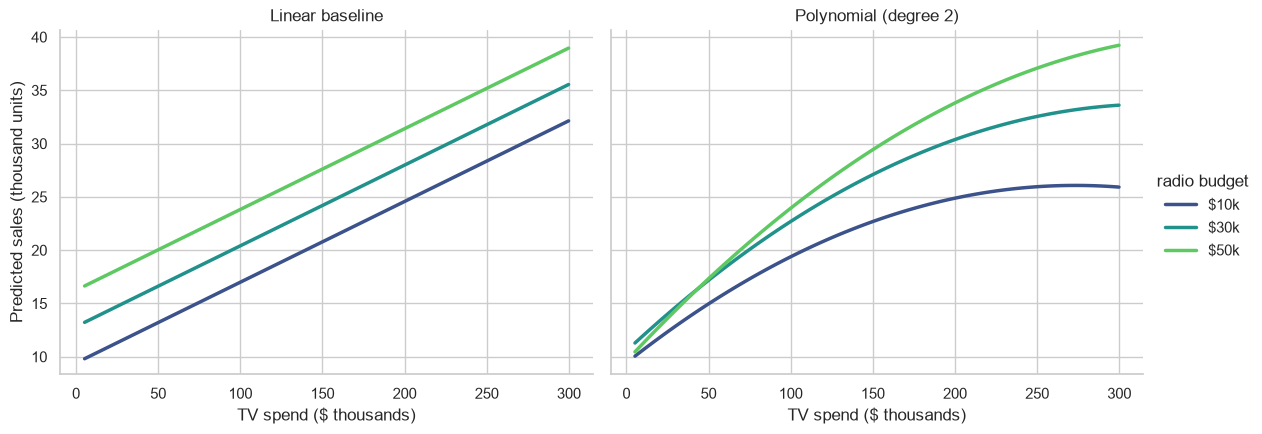

In [37]:
tv_grid = np.linspace(df["tv_spend_k"].min(), df["tv_spend_k"].max(), 100)
radio_levels = [10, 30, 50]
grid = pd.DataFrame([(tv, r) for r in radio_levels for tv in tv_grid],
                    columns=["tv_spend_k", "radio_spend_k"])
grid["social_spend_k"] = df["social_spend_k"].median()

grid_long = pd.concat([
    grid.assign(predicted_sales=baseline.predict(grid[features]), model="Linear baseline"),
    grid.assign(predicted_sales=final_model.predict(grid[features]), model=f"Polynomial (degree {best_degree})"),
])
grid_long["radio budget"] = "$" + grid_long["radio_spend_k"].astype(str) + "k"

g = sns.relplot(data=grid_long, x="tv_spend_k", y="predicted_sales", hue="radio budget",
                col="model", kind="line", lw=2.5, height=4.5, aspect=1.3, palette="viridis")
g.set_axis_labels("TV spend ($ thousands)", "Predicted sales (thousand units)")
g.set_titles("{col_name}")
plt.show()

The polynomial model tells a richer and more realistic story:

- Each curve **flattens** at high TV spend (diminishing returns).
- The curves **spread apart** as TV spend grows: the extra value of a bigger radio budget is larger when TV spend is also high (synergy).

A marketing manager could use this to reason about budget allocation, something the linear model would get systematically wrong.

> **Caution about extrapolation:** polynomials can behave badly **outside** the range of the training data. A quadratic that bends down past the data range will keep plunging forever. Only trust predictions within (or very near) the range of spend levels you trained on.